In [2]:
import sys
sys.path.append("..")

from src.data import load_cmapss

df = load_cmapss("../data/train_FD001.txt")
df.head()

,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [5]:
df["max_cycle"] = df.groupby("unit")["cycle"].transform("max")
df["RUL"] = df["max_cycle"] - df["cycle"]
df.head()

,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,192,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,192,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,192,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,192,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,192,187


In [9]:
settings = ["setting_1", "setting_2", "setting_3"]
sensors = [f"s{i}" for i in range(1, 22)]
features = settings + sensors

n_distintos = df[features].nunique()
n_distintos.sort_values().head(10)

s1            1
setting_3     1
s5            1
s10           1
s18           1
s19           1
s16           1
s6            2
s17          13
setting_2    13
dtype: int64

In [10]:
constantes = n_distintos[n_distintos == 1].index.tolist()
print(constantes)

['setting_3', 's1', 's5', 's10', 's16', 's18', 's19']


In [11]:
utiles = [c for c in features if c not in constantes]
print(len(utiles), utiles)

17 ['setting_1', 'setting_2', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


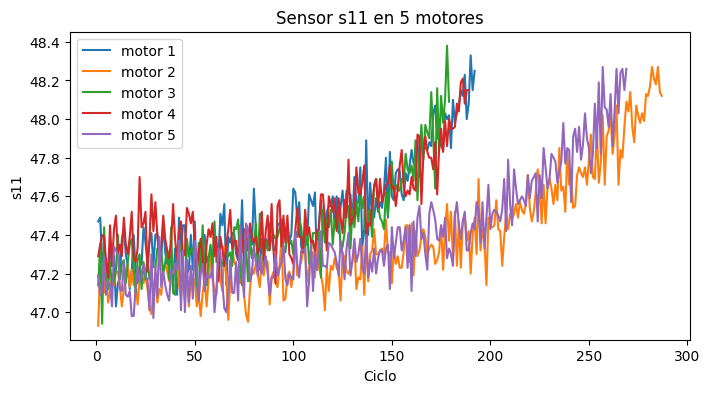

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for u in [1, 2, 3, 4, 5]:
    motor = df[df["unit"] == u]
    ax.plot(motor["cycle"], motor["s11"], label=f"motor {u}")
ax.set_xlabel("Ciclo")
ax.set_ylabel("s11")
ax.set_title("Sensor s11 en 5 motores")
ax.legend()
plt.show()

In [13]:
df[utiles + ["RUL"]].corr()["RUL"].sort_values()

s11         -0.696228
s4          -0.678948
s15         -0.642667
s2          -0.606484
s17         -0.606154
s3          -0.584520
s8          -0.563968
s13         -0.562569
s9          -0.390102
s14         -0.306769
s6          -0.128348
setting_1   -0.003198
setting_2   -0.001948
s20          0.629428
s21          0.635662
s7           0.657223
s12          0.671983
RUL          1.000000
Name: RUL, dtype: float64